# CRISP-DM — Telecom churn outreach demonstration

See report.md for the consolidated final report and README.md for reproduction instructions. Earlier drafts retain their original wording and pending-status statements as a revision history; final phase notes and the report supersede those statements.

Packaging cleanup removed an empty opening code cell and an exact duplicate Evaluation final-revision cell. All other original cells and recorded outputs are preserved.

# Telecom Customer Churn Using CRISP-DM

## Phase 1 — Business Understanding
### Initial draft

**Business objective.** A telecom retention team has limited time to contact customers. The goal is to use customer account information to decide which customers to contact first.

**Situation and constraints.** The dataset includes contract type, tenure, services, and charges. It records whether each customer left, but it does not record whether a retention offer would have changed that decision. For this project, I assume the team can contact 10% of customers.

**Data mining goal and success criteria.** I will build a model that ranks customers by their estimated likelihood of churn. On held-out data, I will check whether the top-ranked 10% contains a higher percentage of customers who actually left than the test set overall. This compares the model with selecting customers at random under the same contact limit.

**Project plan.** I will inspect the data, prepare the features, compare classification models, evaluate the final ranking, and demonstrate how to score a new customer account.

### Phase 1 Critique — Round 1

This was the answer form the prompt:


1. **Business objective.** The draft defines the decision the team faces, but it leaves “contact first” open to two interpretations. Customers most likely to leave may be different from those most likely to stay because someone called. The churn label supports evaluating the first group. **Clarify that the immediate objective is to help the team reach more customers at risk of leaving within its limited outreach capacity.** An actual reduction in churn would need to be measured separately.
2. **Situation and constraints.** You correctly identify 10% as an assumption. The weakness is the missing denominator. Ten percent of all historical accounts and 10% of active accounts eligible for a call can mean different workloads. **Define who is eligible when the list is created and apply the 10% limit to that group.** For example, you could assume the team can contact 10% of accounts that are active at the start of each outreach cycle. Both the capacity and the cycle are planning assumptions.
3. **Data mining goal and success criteria.** The random-selection comparison fits the contact limit, but “higher” allows even a negligible gain to count as success. **Specify the minimum gain that would make the ranking worthwhile**, ideally in terms the team can judge, such as how many additional customers who later churn it would want to reach per 100 calls compared with random selection. Held-out data can estimate the gain. The minimum worthwhile gain is a business judgment.
4. **Project plan.** Scoring one new account demonstrates that the model produces a score, but the team’s decision depends on how that account ranks against others. **Plan to demonstrate one complete outreach list** by scoring a batch of eligible accounts, sorting them by risk, and selecting the top 10%. Historical accounts can illustrate how the team would use the list. Demonstrating that the calls prevented cancellations would require outreach results.

### Phase 1 — Business Understanding — Revision 1

**1. Business objective.** The retention team wants to use its limited calls to reach more customers at risk of leaving. I will build a ranked list to help the team decide whom to call first. The historical churn labels let me check how many customers on that list actually left. Measuring whether a call helped someone stay would require a separate outreach experiment.

**2. Situation and constraints.** For this project, I assume the team creates a list once a month. Eligible customers are those with an active account at the start of that month, and the team can call up to 10% of them. The monthly schedule and call limit are planning assumptions. Since the CSV has no dated account snapshots, I will use the held-out accounts as a sample outreach group and document that limitation.

**3. Data mining goal and success criteria.** I will rank the held-out accounts by predicted churn risk and select the top 10%. My proposed success target is to identify at least 10 additional customers who churned per 100 calls compared with random selection. For example, if 26% of the held-out group churned, the selected list would need a churn rate of at least 36% to meet the target. These numbers illustrate the calculation. I will use the actual held-out churn rate for the evaluation.

**4. Project plan.** I will check the data quality, prepare the features, and compare models on validation data. After choosing a model, I will score a held-out batch, sort the accounts from highest to lowest risk, and select the top 10%, rounding down to stay within capacity. The final output will be a sample call list with customer ID, risk score, and rank. I will use the historical churn labels only after the list is created to check whether it meets the success target.

### Phase 1 Critique — Round 2

| Round 1 comment                     | Status       | Reason                                                                                                                                                                                                                                                                                                                                                  |
| ----------------------------------- | ------------ | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1. Clarify the business objective   | **Resolved** | The decision is clear: whom should the team call first? Historical churn labels let you count how many selected customers left. You correctly reserve the question of whether calls helped customers stay for a separate experiment.                                                                                                                    |
| 2. Define the outreach group        | **Resolved** | Customers with active accounts at the start of each month form the eligible group, and the 10% cap applies to that group. You identify the monthly schedule and capacity as assumptions and explain why held-out accounts can only stand in for a real monthly group.                                                                                   |
| 3. Set a measurable success target  | **Resolved** | Subtract the overall held-out churn rate from the selected list’s churn rate. A difference of at least **10 percentage points** meets the target. Your 26% to 36% example is correct because random selection would match the overall rate on average. The threshold is a proposed business target, and the data can show whether the ranking meets it. |
| 4. Demonstrate a complete call list | **Resolved** | Customer ID tells the team whom to call, rank tells it whom to call first, and rounding down keeps the list within capacity. Checking churn labels after selection lets you evaluate the list without using the answers to build it.                                                                                                                    |

**Most important remaining improvement:** Define the churn time window. A monthly call schedule tells the team *when to act*, but “at risk of leaving” leaves open *how soon*. If the team wants to reach customers likely to leave before the next monthly list, state that as the intended window. Without dated snapshots, the historical evaluation can show whether the list contains a higher share of customers labeled as having churned. It cannot establish how well the list predicts departures during that specific month.

### Phase 1 — Business Understanding — Final Revision

**1. Business objective.** At the start of each month, the retention team wants to decide which active customers to call first. The goal is to reach customers at risk of leaving before the next monthly call list is created. Measuring whether a call actually prevented a cancellation would require a separate outreach experiment.

**2. Situation and constraints.** I assume the team can call up to 10% of the accounts active at the start of each month. The monthly schedule and call limit are project assumptions. The CSV contains account details and a historical churn label, but it has no dated account snapshots to connect each prediction to a departure in the following month. I will use held-out accounts to simulate one outreach cycle. This lets me evaluate how well the ranking identifies historical churners. Its accuracy for the intended one-month window remains unverified.

**3. Data mining goal and success criteria.** I will compare the churn rate among the top-ranked 10% with the churn rate across all held-out accounts, which is the expected rate under random selection. My proposed success target is a difference of at least 10 percentage points. For example, if 26% of the held-out accounts churned, at least 36% of the selected accounts would need to have churned to meet the target.

**4. Project plan.** I will check data quality, prepare the features, and compare models on validation data. I will use the chosen model to score the held-out accounts, sort them by risk, and select the top 10%, rounding down to stay within capacity. The sample call list will include customer ID, risk score, and rank. After creating the list, I will use the held-out churn labels to calculate whether it meets the success target.

## Phase 2 — Data Understanding
### 2.1 Collect the initial data

I am using the [Telco Customer Churn dataset from Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). I will load the original CSV and check its dimensions, preview the account records, and confirm the values in the `Churn` column.

In [16]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())
print(df["Churn"].value_counts())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn
No     5174
Yes    1869
Name: count, dtype: int64


### 2.2 Describe the data and verify its quality

In [17]:
summary = pd.DataFrame({
    "Data type": df.dtypes,
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique()
})
display(summary)

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
invalid_charges = total_charges_numeric.isna()

print("Missing or nonnumeric TotalCharges:", invalid_charges.sum())
display(df.loc[invalid_charges, [
    "customerID", "tenure", "MonthlyCharges", "TotalCharges"
]])

display(df.describe(include="all").T)


,Data type,Missing values,Unique values
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


Duplicate rows: 0
Duplicate customer IDs: 0
Missing or nonnumeric TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data-quality findings

The dataset contains 7,043 unique customer accounts and 21 columns. There are no duplicate rows or customer IDs. Although the initial missing-value check reports zero missing values, converting TotalCharges to numeric reveals 11 blank entries. All 11 accounts have zero tenure. This suggests new accounts, although the reason for the missing charges is unconfirmed.

TotalCharges needs numeric conversion and missing-value handling during preparation. SeniorCitizen is a binary category stored as an integer. CustomerID identifies accounts and will be retained for the outreach list but excluded from model inputs.

Tenure ranges from 0 to 72 months, and MonthlyCharges ranges from 18.25 to 118.75. The dataset contains 1,869 customers labeled Yes for churn and 5,174 labeled No, giving an overall churn rate of approximately 26.54%.

### 2.3 Explore the data

Before exploring relationships with churn, I will reserve validation and test sets. I will use the training set to examine patterns in contract type, tenure, and monthly charges. This keeps detailed exploration focused on the data used to develop the model.


Training rows: 4225
Validation rows: 1409
Test rows: 1409


,Customers,Churn rate (%)
Contract,,
Month-to-month,2304,43.06
One year,896,11.05
Two year,1025,2.93


tenure        MonthlyCharges       
        mean median           mean median
Churn                                    
No     37.55   38.0          61.29   64.4
Yes    18.31   10.0          74.86   80.0

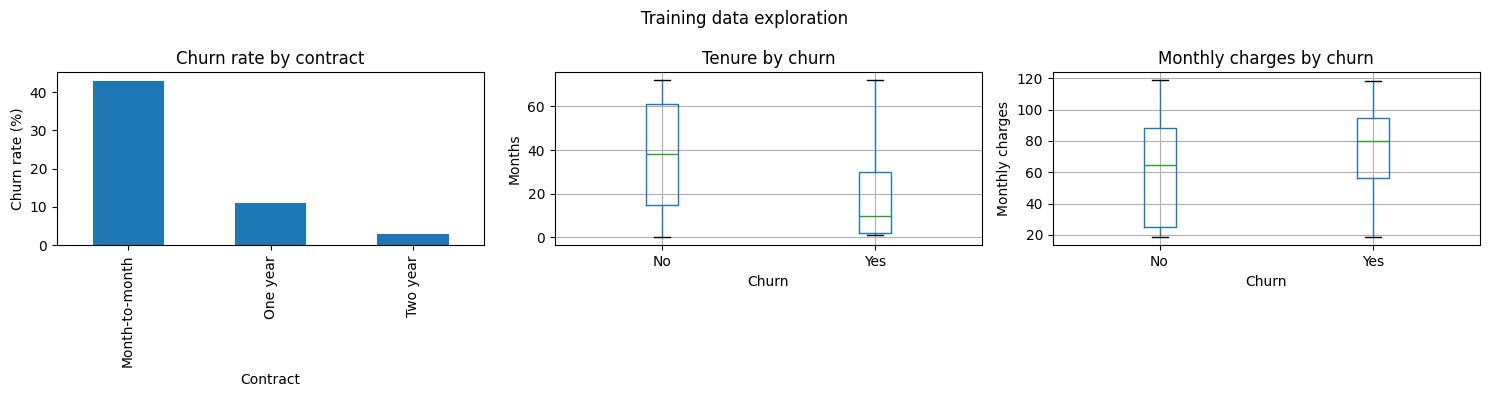

In [18]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

train_df, remaining_df = train_test_split(
    df, test_size=0.40, stratify=df["Churn"], random_state=42
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["Churn"],
    random_state=42
)

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

contract_summary = (
    train_df.assign(churn_flag=train_df["Churn"].eq("Yes"))
    .groupby("Contract")["churn_flag"]
    .agg(["count", "mean"])
    .rename(columns={"count": "Customers", "mean": "Churn rate"})
)
contract_summary["Churn rate (%)"] = contract_summary.pop("Churn rate") * 100
display(contract_summary.round(2))

display(
    train_df.groupby("Churn")[["tenure", "MonthlyCharges"]]
    .agg(["mean", "median"])
    .round(2)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

contract_summary["Churn rate (%)"].plot.bar(
    ax=axes[0], title="Churn rate by contract"
)
axes[0].set_ylabel("Churn rate (%)")

train_df.boxplot(column="tenure", by="Churn", ax=axes[1])
axes[1].set_title("Tenure by churn")
axes[1].set_ylabel("Months")

train_df.boxplot(column="MonthlyCharges", by="Churn", ax=axes[2])
axes[2].set_title("Monthly charges by churn")
axes[2].set_ylabel("Monthly charges")

fig.suptitle("Training data exploration")
plt.tight_layout()
plt.show()

### Exploration findings — Initial draft

In the training data, month-to-month customers have a churn rate of 43.06%, compared with 11.05% for one-year contracts and 2.93% for two-year contracts. The groups contain 2,304, 896, and 1,025 customers, respectively.

Customers who churned have a median tenure of 10 months, compared with 38 months for customers who stayed. Their median monthly charge is also higher, at 80.00 compared with 64.40.

These patterns suggest that contract type, tenure, and monthly charges may help predict churn. They show associations, and further modeling is needed to assess their combined predictive value. The boxplots also show overlap between customers who stayed and those who left.

The stratified split contains 4,225 training accounts, 1,409 validation accounts, and 1,409 test accounts. Initial data-quality checks covered the full dataset, while the relationship analysis above uses only training accounts.


### Phase 2 Critique — Round 1

Your exploration findings match the screenshot. The remaining gaps mainly concern documenting data provenance, clarifying missing-value detection, and recording checks that have yet to be performed.

1. **Collect initial data**

   **Adequately covered.** You identify the source URL, filename, loading environment, and initial inspection steps. The reported label counts sum to 7,043, and 1,869 ÷ 7,043 gives approximately 26.54% churn.

   **Gap and why it matters.** The collection description does not record the download date or explain the dataset’s original provenance and intended population. This limits reproducibility and leaves uncertainty about how well these accounts represent the telecom customers your simulated team would contact.

   **Concrete improvement.** Record the download date and briefly summarize what the source documentation establishes about the dataset’s origin and churn definition. Explicitly mark unavailable information, including account observation dates. The attached screenshot supports the exploration results, but it does not independently confirm the loading output or full-dataset label counts.

2. **Describe data**

   **Adequately covered.** You list all 21 columns and explain their main roles. Your treatment of `SeniorCitizen` as categorical, `TotalCharges` as requiring numeric interpretation, and `customerID` as an identifier is appropriate. Use the exact spelling `customerID` consistently.

   **Gap and why it matters.** You describe having displayed types and unique-value counts, but provide little detail about actual category values. Storage types alone do not establish meaning. Service fields may contain categories such as “No internet service,” whose meaning differs from a customer declining an individual service. These distinctions affect interpretation of potential churn predictors.

   **Concrete improvement.** Summarize the observed values of categorical fields and distinguish identifiers, categories, numeric measurements, and the target. Confirm the units of tenure and charges from documentation. The reported tenure and charge ranges are not shown in this screenshot, so their exact endpoints remain supported by your written report rather than independently visible output.

3. **Explore data**

   **Adequately covered.** The screenshot confirms both stratified splitting calls, `random_state=42`, and the 4,225/1,409/1,409 partition sizes. It also confirms every reported contract count, churn percentage, mean, and median. The relationship summaries and charts use `train_df`, and the boxplots support your observation that the groups overlap.

   **Gap and why it matters.** The screenshot does not display churn proportions in each partition or an explicit overlap check. Stratification is correctly requested, but recording its result makes the evaluation setup easier to verify. Also, these three relationships cannot establish that they are the strongest predictors.

   **Concrete improvement.** Report each partition’s churn count and percentage, and confirm that customer IDs do not overlap across partitions. State that validation supports model selection and the test set remains reserved for final evaluation. Your association language is appropriately cautious. Keep the interpretation limited to the relationships examined. The random split supports historical evaluation, while performance for a future month remains unverified.

4. **Verify data quality**

   **Adequately covered.** You report checks for pandas-recognized missing values, duplicate rows, duplicate IDs, and numeric conversion failures. Inspecting the 11 affected rows adds useful evidence. You also correctly treat “new accounts” as a possible explanation requiring confirmation.

   **Gap and why it matters.** Zero results from `isna()` do not establish that all fields are complete, because blank strings can remain ordinary text. Your `TotalCharges` check demonstrates this limitation. The draft also leaves category consistency and numeric plausibility checks undocumented, which could conceal values that distort customer comparisons.

   **Concrete improvement.** Check string columns for empty or whitespace-only values and inconsistent category labels. Check numeric fields for negative or otherwise implausible values and confirm that `SeniorCitizen` contains only its expected binary values. Record these as pending until executed. The screenshot does not show the reported quality-check outputs, so those checks are documented in your narrative but cannot be independently verified from this image. Conversion and missing-value treatment remain planned work.

**The most important remaining improvement is to make the quality assessment explicit about what each check establishes.** Separate pandas-recognized nulls, blank strings, conversion failures, and pending validity checks. This will prevent “zero missing values” from being read as a conclusion that the dataset is complete.

In [19]:
# Check nulls and blank strings separately.
text_columns = df.select_dtypes(include=["object", "string"]).columns

blank_counts = df[text_columns].apply(
    lambda column: column.astype("string").str.strip().eq("").sum()
)

quality_summary = pd.DataFrame({
    "Pandas nulls": df.isna().sum(),
    "Blank strings": blank_counts.reindex(df.columns, fill_value=0)
})
display(quality_summary)

# Inspect category values and possible spelling/spacing differences.
category_columns = [
    column for column in text_columns
    if column not in ["customerID", "TotalCharges"]
]

for column in category_columns:
    values = df[column].dropna().astype(str)
    normalized = values.str.strip().str.casefold()
    print(f"\n{column}: {sorted(values.unique())}")
    print("Values with surrounding spaces:", values.ne(values.str.strip()).sum())
    print("Labels merged by normalizing case/spaces:",
          values.nunique() - normalized.nunique())

# Check numeric conversion, negative values, and binary validity.
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
numeric_data = df[numeric_columns].apply(pd.to_numeric, errors="coerce")

numeric_checks = pd.DataFrame({
    "Missing after conversion": numeric_data.isna().sum(),
    "Negative values": numeric_data.lt(0).sum(),
    "Minimum": numeric_data.min(),
    "Maximum": numeric_data.max()
})
display(numeric_checks)

print("SeniorCitizen values:", sorted(df["SeniorCitizen"].dropna().unique()))
print("Invalid SeniorCitizen values:",
      (~df["SeniorCitizen"].isin([0, 1])).sum())
print("Non-integer tenure values:",
      numeric_data["tenure"].dropna().mod(1).ne(0).sum())

# Verify partition sizes, churn proportions, and separation.
partitions = {"Training": train_df, "Validation": val_df, "Test": test_df}

split_summary = pd.DataFrame({
    name: {
        "Accounts": len(partition),
        "Churn Yes": partition["Churn"].eq("Yes").sum(),
        "Churn (%)": partition["Churn"].eq("Yes").mean() * 100
    }
    for name, partition in partitions.items()
}).T
display(split_summary.round(2))

train_ids = set(train_df["customerID"])
val_ids = set(val_df["customerID"])
test_ids = set(test_df["customerID"])

print("Training/validation overlap:", len(train_ids & val_ids))
print("Training/test overlap:", len(train_ids & test_ids))
print("Validation/test overlap:", len(val_ids & test_ids))
print("All accounts included:",
      train_ids | val_ids | test_ids == set(df["customerID"]))

,Pandas nulls,Blank strings
customerID,0,0
gender,0,0
SeniorCitizen,0,0
Partner,0,0
Dependents,0,0
tenure,0,0
PhoneService,0,0
MultipleLines,0,0
InternetService,0,0
OnlineSecurity,0,0



gender: ['Female', 'Male']
Values with surrounding spaces: 0
Labels merged by normalizing case/spaces: 0

Partner: ['No', 'Yes']
Values with surrounding spaces: 0
Labels merged by normalizing case/spaces: 0

Dependents: ['No', 'Yes']
Values with surrounding spaces: 0
Labels merged by normalizing case/spaces: 0

PhoneService: ['No', 'Yes']
Values with surrounding spaces: 0
Labels merged by normalizing case/spaces: 0

MultipleLines: ['No', 'No phone service', 'Yes']
Values with surrounding spaces: 0
Labels merged by normalizing case/spaces: 0

InternetService: ['DSL', 'Fiber optic', 'No']
Values with surrounding spaces: 0
Labels merged by normalizing case/spaces: 0

OnlineSecurity: ['No', 'No internet service', 'Yes']
Values with surrounding spaces: 0
Labels merged by normalizing case/spaces: 0

OnlineBackup: ['No', 'No internet service', 'Yes']
Values with surrounding spaces: 0
Labels merged by normalizing case/spaces: 0

DeviceProtection: ['No', 'No internet service', 'Yes']
Values wi

,Missing after conversion,Negative values,Minimum,Maximum
tenure,0,0,0.00,72.00
MonthlyCharges,0,0,18.25,118.75
TotalCharges,11,0,18.80,8684.80


SeniorCitizen values: [np.int64(0), np.int64(1)]
Invalid SeniorCitizen values: 0
Non-integer tenure values: 0


,Accounts,Churn Yes,Churn (%)
Training,4225.0,1121.0,26.53
Validation,1409.0,374.0,26.54
Test,1409.0,374.0,26.54


Training/validation overlap: 0
Training/test overlap: 0
Validation/test overlap: 0
All accounts included: True


### Phase 2 — Data Understanding — Revision 1

#### 1. Collect initial data

I downloaded WA_Fn-UseC_-Telco-Customer-Churn.csv from Kaggle and loaded it into Google Colab using pandas.

Download date — 11-03-26

Source — https://www.kaggle.com/datasets/blastchar/telco-customer-churn

The Kaggle description attributes the dataset to IBM sample data and describes each row as one customer. Churn indicates whether the customer left within the last month. The source supports using the sample to explore customer retention.

The CSV contains no dated account snapshots or cancellation dates. The exact calendar period and whether these accounts represent a current telecom customer population remain unverified. Historical evaluation therefore cannot establish performance for the following month.

#### 2. Describe data

The dataset contains 7,043 customer accounts and 21 columns. There are 1,869 Yes churn labels and 5,174 No labels, giving an overall churn rate of approximately 26.54%.

customerID is the identifier, Churn is the target, and tenure, MonthlyCharges, and TotalCharges are numeric measurements. SeniorCitizen is a binary category stored as 0 or 1. The remaining predictors describe demographics, services, contracts, and payment arrangements.

Observed categories include:
- Contract — Month-to-month, One year, Two year.
- InternetService — DSL, Fiber optic, No.
- MultipleLines — Yes, No, No phone service.
- Internet add-on services — Yes, No, No internet service.
- PaymentMethod — Bank transfer (automatic), Credit card (automatic), Electronic check, Mailed check.
- gender — Female, Male.
- Partner, Dependents, PhoneService, PaperlessBilling, and Churn — Yes, No.

“No internet service” and “No phone service” describe the absence of the underlying service. They are meaningful categories and will be retained separately from “No.”

Tenure is interpreted as months with the company. MonthlyCharges and TotalCharges represent monthly and accumulated charges. The currency has not been verified from the source documentation consulted.

customerID will identify accounts in the final outreach list and will be excluded from model inputs.

#### 3. Explore data

I used two stratified splits with random_state=42 to create the following partitions.

| Partition | Accounts | Churn Yes | Churn percentage |
|---|---:|---:|---:|
| Training | 4,225 | 1,121 | 26.53% |
| Validation | 1,409 | 374 | 26.54% |
| Test | 1,409 | 374 | 26.54% |

All accounts are included, and no customer IDs overlap between partitions. Training data supports exploration and fitting, validation data supports model selection, and test data is reserved for final model evaluation.

In the training set, churn rates are 43.06% for month-to-month contracts, 11.05% for one-year contracts, and 2.93% for two-year contracts.

Customers who churned have a median tenure of 10 months and median monthly charges of 80.00. Customers who stayed have a median tenure of 38 months and median monthly charges of 64.40.

The charts show associations between these variables and churn, with overlapping distributions. Their combined predictive value will be assessed during modeling.

#### 4. Verify data quality

Completed checks found:
- Zero pandas-recognized nulls in the original data.
- Eleven whitespace-only TotalCharges entries and zero blank strings in other text columns.
- Eleven missing values after numeric conversion of TotalCharges, corresponding to the blank entries.
- Zero duplicate rows and zero duplicate customer IDs.
- Zero surrounding-space issues or category labels merged by normalizing capitalization and spaces in the checked categorical fields.
- Zero negative values in tenure, MonthlyCharges, or numeric TotalCharges.
- Only 0 and 1 in SeniorCitizen.
- Zero non-integer tenure values.

Observed numeric ranges are:
- tenure — 0 to 72.
- MonthlyCharges — 18.25 to 118.75.
- Nonmissing TotalCharges — 18.80 to 8,684.80.

All 11 accounts with blank TotalCharges have zero tenure. Their status as new accounts is a possible explanation, but the reason for the blanks remains unconfirmed.

These checks establish basic consistency within the file. They do not independently verify every recorded value against customer records. Numeric conversion and missing-value treatment will be implemented during Data Preparation.

Structural and quality checks covered the full dataset. Detailed relationships with churn were explored using training data.

### Phase 2 Critique — Round 2

1. **Collect initial data — Partly resolved.**  
   The provenance and historical churn definition are now supported. Kaggle attributes the material to IBM sample data, describes each row as a customer, and defines `Churn` as leaving within the last month. Your qualification about the unknown calendar period and current representativeness is appropriate. The remaining issue is the download-date placeholder. Enter the actual date if known, or state that it was not recorded. [kaggle.com](https://www.kaggle.com/blastchar/telco-customer-churn?utm_source=chatgpt.com)

2. **Describe data — Resolved, with one wording clarification.**  
   Every category list in the revision matches the attached outputs, including the service-absence categories and payment methods. The output also confirms `SeniorCitizen` contains only 0 and 1. Distinguishing meaningful service categories and leaving currency unverified addresses the earlier concerns.

   Restore the distinction between meaning and storage for `TotalCharges`. It represents a numeric measurement, but the original column was loaded as text/object. Calling it a numeric measurement is accurate, provided readers understand that conversion is still needed in the preparation workflow. The partition counts also support the reported total accounts and churn-label counts.

3. **Explore data — Resolved.**  
   The attached outputs exactly match your partition sizes, churn counts, and percentages. They report zero overlap for all three partition pairs and confirm that all accounts are included. The earlier screenshot supports the two stratified splits, training-only relationship exploration, contract churn rates, and reported medians.

   Your description of training, validation, and test roles is clear. The interpretation stays at association and appropriately leaves combined predictive value for later assessment. Keeping an explicit statement that these relationships do not establish causation would preserve the clarity of your initial draft. The limitation concerning future-month performance remains correctly documented.

4. **Verify data quality — Partly resolved.**  
   The attachment supports zero original pandas nulls, 11 blank `TotalCharges` entries, zero blanks elsewhere, and 11 missing values after conversion. It also supports every reported numeric range, zero negative values, valid `SeniorCitizen` values, integer tenure, and the reported category-spacing and normalization checks.

   Two evidence gaps remain. The supplied attachment does not display the duplicate-row or duplicate-ID results, or the affected rows showing zero tenure for all 11 blank charges. These were reported earlier as completed, but their outputs remain unavailable for independent confirmation. Include those existing outputs with the final evidence.

   Also clarify that numeric conversion **was already performed diagnostically** to generate the checks, while applying conversion and missing-value treatment to the preparation workflow remains planned. The blank count and conversion-missing count agree, but the attachment alone does not directly show their row-by-row correspondence. Preserve the earlier affected-row output to substantiate that claim.

**The main remaining improvement is evidence completeness.** Fill the download-date placeholder and include the already-reported duplicate and affected-row outputs. Keep the explanation that zero tenure may indicate new accounts explicitly tentative. Your completed checks support basic file consistency, while the reason for missing charges, real-world accuracy, and future-month applicability remain unverified.


In [20]:
blank_charges = df["TotalCharges"].astype("string").str.strip().eq("")
converted_charges = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Blank TotalCharges entries:", blank_charges.sum())
print(
    "Blank rows exactly match missing values after conversion:",
    blank_charges.eq(converted_charges.isna()).all()
)
print(
    "All accounts with blank TotalCharges have zero tenure:",
    df.loc[blank_charges, "tenure"].eq(0).all()
)

display(df.loc[blank_charges, [
    "customerID", "tenure", "MonthlyCharges", "TotalCharges"
]])

Duplicate rows: 0
Duplicate customer IDs: 0
Blank TotalCharges entries: 11
Blank rows exactly match missing values after conversion: True
All accounts with blank TotalCharges have zero tenure: True


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


### Phase 2 — Data Understanding — Final Revision

This note incorporates the second critique into Revision 1.

**Collection date.** The exact download date was not recorded. The dataset was uploaded to this project on November 2, 2026.

**Meaning and storage.** TotalCharges represents accumulated charges, but pandas originally loaded it as an object/text column. Numeric conversion was performed diagnostically in a separate variable to inspect missing values and numeric ranges. Applying conversion and missing-value treatment to the modeling inputs remains part of Data Preparation.

**Interpretation.** The observed relationships between contract type, tenure, monthly charges, and churn show associations. They do not establish causation.

**Evidence completeness.** The accompanying verification cell reports duplicate rows and duplicate customer IDs, displays the accounts with blank TotalCharges, and checks whether the blank entries exactly match the values missing after diagnostic conversion. It also checks whether all affected accounts have zero tenure.

Zero tenure may indicate new accounts, but the reason for their missing charges remains unconfirmed. The checks assess consistency within this file. Real-world accuracy and predictive performance for a future month remain unverified.

## Phase 3 — Data Preparation
### Initial draft

#### Select data
I will retain all accounts in the existing training, validation, and test partitions. Churn is the target. customerID will be stored separately for the outreach list. The remaining 19 columns will be model inputs.

#### Clean data
I will convert TotalCharges to numeric, which represents its blank entries as missing values. During preprocessing, missing numeric values will be filled using medians learned only from the training data. This is a practical imputation choice because the true missing charges are unknown.

#### Construct data
I will encode Churn as 1 for Yes and 0 for No. I will retain the original predictors without adding derived features for the initial models.

#### Integrate data
The project uses one CSV, so no external joins are needed. The existing partitions and customer identifiers will preserve the relationship between each account, its predictors, and its label.

#### Format data
I will treat SeniorCitizen as categorical. Categorical predictors will be one-hot encoded, preserving service-absence categories. Numeric predictors will be standardized for models that benefit from scaling. Preprocessing will be fitted on training data and applied to validation and test data.

In [21]:
def prepare_partition(partition):
    customer_ids = partition["customerID"].copy()
    y = partition["Churn"].map({"No": 0, "Yes": 1})

    X = partition.drop(columns=["customerID", "Churn"]).copy()
    X["TotalCharges"] = pd.to_numeric(X["TotalCharges"], errors="coerce")
    X["SeniorCitizen"] = X["SeniorCitizen"].astype(str)

    assert y.notna().all(), "Unexpected or missing Churn label"
    assert X.index.equals(y.index)
    assert X.index.equals(customer_ids.index)

    return X, y, customer_ids


X_train, y_train, train_customer_ids = prepare_partition(train_df)
X_val, y_val, val_customer_ids = prepare_partition(val_df)
X_test, y_test, test_customer_ids = prepare_partition(test_df)

preparation_summary = pd.DataFrame({
    "Partition": ["Training", "Validation", "Test"],
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Predictors": [
        X_train.shape[1], X_val.shape[1], X_test.shape[1]
    ],
    "Missing TotalCharges": [
        X_train["TotalCharges"].isna().sum(),
        X_val["TotalCharges"].isna().sum(),
        X_test["TotalCharges"].isna().sum()
    ]
})

display(preparation_summary)
print("TotalCharges type:", X_train["TotalCharges"].dtype)
print("SeniorCitizen type:", X_train["SeniorCitizen"].dtype)
print("Target values:", sorted(y_train.unique()))

,Partition,Rows,Predictors,Missing TotalCharges
0,Training,4225,19,7
1,Validation,1409,19,1
2,Test,1409,19,3


TotalCharges type: float64
SeniorCitizen type: object
Target values: [np.int64(0), np.int64(1)]


In [22]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)

display(pd.DataFrame({
    "Partition": ["Training", "Validation", "Test"],
    "Rows": [
        X_train_prepared.shape[0],
        X_val_prepared.shape[0],
        X_test_prepared.shape[0]
    ],
    "Prepared features": [
        X_train_prepared.shape[1],
        X_val_prepared.shape[1],
        X_test_prepared.shape[1]
    ],
    "All values finite": [
        np.isfinite(X_train_prepared).all(),
        np.isfinite(X_val_prepared).all(),
        np.isfinite(X_test_prepared).all()
    ]
}))

learned_medians = (
    preprocessor.named_transformers_["numeric"]
    .named_steps["imputer"]
    .statistics_
)

display(pd.DataFrame({
    "Feature": numeric_features,
    "Training median": X_train[numeric_features].median().to_numpy(),
    "Imputer median": learned_medians
}))

assert np.allclose(
    learned_medians,
    X_train[numeric_features].median().to_numpy()
)
assert X_train_prepared.shape[1] == X_val_prepared.shape[1]
assert X_train_prepared.shape[1] == X_test_prepared.shape[1]

print("Checks passed: imputation uses training medians and feature counts match.")

,Partition,Rows,Prepared features,All values finite
0,Training,4225,46,True
1,Validation,1409,46,True
2,Test,1409,46,True


,Feature,Training median,Imputer median
0,tenure,29.000,29.000
1,MonthlyCharges,70.550,70.550
2,TotalCharges,1373.625,1373.625


Checks passed: imputation uses training medians and feature counts match.


### Data Preparation — Initial results

All accounts were retained, with 4,225 training rows, 1,409 validation rows, and 1,409 test rows. Removing customerID and separating Churn left 19 predictors.

TotalCharges was converted to numeric. Its 11 missing values were distributed across training, validation, and test as 7, 1, and 3. Missing numeric values were filled using training medians. The learned medians were 29 for tenure, 70.55 for MonthlyCharges, and 1,373.625 for TotalCharges.

SeniorCitizen was treated as categorical. One-hot encoding expanded the categorical predictors, producing 46 prepared features in total. Service-absence categories were retained. Unknown categories are handled by encoding all indicators for that field as zero.

Numeric features were standardized after imputation. The preprocessor was fitted on training data and applied to validation and test data. All three resulting arrays contain finite values and have matching feature counts.

The assertions confirmed that features, labels, and customer identifiers were aligned before transformation. Customer identifiers remain stored separately for the outreach list. No external joins or derived predictors were added.

### Phase 3 Critique - Round 1

Your preparation process preserves the partitions and describes fitting preprocessing only on training data. The main unresolved decision is how to justify imputing accumulated charges for accounts with zero tenure. The reported checks establish consistent dimensions, finite values, and matching imputation medians, but they do not establish that the imputed charges are realistic.

1. **Select data**

   **Adequately covered.** Retaining all accounts preserves the existing split. Separating `customerID` and `Churn` leaves the expected 19 predictors, while retaining identifiers supports the final outreach list.

   **Weakness and significance.** The selection is documented, but its rationale is brief. Readers need to understand why all remaining fields are included and whether they could be available when an outreach list is created.

   **Concrete improvement.** Explain that the 19 fields are retained as initial candidate predictors based on their account, service, and demographic information. Explicitly acknowledge that their availability before churn cannot be fully verified without dated snapshots. Add a direct check that neither `customerID` nor `Churn` appears in the preprocessing inputs or generated feature names.

2. **Clean data**

   **Adequately covered.** The missing-value counts total 11 and agree with the earlier findings. Training-only median imputation avoids learning replacement values from held-out accounts. The reported imputer statistics match the training medians.

   **Weakness and significance.** A `TotalCharges` replacement of 1,373.625 may poorly represent a zero-tenure account. Matching the training median verifies the implementation, but provides no evidence that this amount approximates those customers’ actual accumulated charges. Zero tenure alone also does not establish that their charges should be zero.

   **Concrete improvement.** Retain median imputation as an explicitly provisional choice and explain this limitation. Inspect the affected training accounts after preparation to document the replacements. If reconsidering the rule, use training evidence or documented billing semantics to justify it. Your categorical imputer is a reasonable fallback, but describe it as configured protection because no categorical gaps were observed.

3. **Construct data**

   **Adequately covered.** The target mapping is explicit, and converting `SeniorCitizen` to strings makes its categorical treatment clear. Adding no derived predictors is acceptable for this initial preparation.

   **Weakness and significance.** Checking only for missing mapped labels does not independently establish that every label retained the intended meaning. A reversed mapping could still produce complete numeric labels and would reverse the interpretation of churn scores.

   **Concrete improvement.** Confirm that every original `Yes` maps to 1 and every `No` maps to 0, with unchanged class counts in each partition. Briefly justify using the original predictors initially, with additional feature construction left contingent on evidence.

4. **Integrate data**

   **Adequately covered.** A single source requires no joins, and the index assertions address alignment among predictors, targets, and identifiers before transformation.

   **Weakness and significance.** The prepared arrays may no longer carry pandas indices. The reported assertions therefore do not show how transformed rows will remain connected to customer IDs when building the outreach list.

   **Concrete improvement.** Preserve the original partition index alongside each transformed matrix, or use a labeled representation. Confirm that transformed row counts match the corresponding identifier and target lengths and that their order remains unchanged. This protects the mapping between each customer and their eventual score.

5. **Format data**

   **Adequately covered.** The numeric and categorical pipelines are clearly specified. Scaling accommodates differences in numeric units, while one-hot encoding preserves separate service categories. Your description of unseen-category handling is accurate. The reported results establish 46 features in every partition and finite transformed values.

   **Weakness and significance.** Equal feature counts alone do not establish identical feature meanings or order. Matching imputation medians also does not independently verify how the scaler and encoder were fitted.

   **Concrete improvement.** Record the fitted transformer’s output feature names and confirm that the same fitted transformer supplies the feature order for all partitions. Document that its scaler statistics and encoder categories were learned from training data. Treat all-zero encoding as a fallback for unseen categories, with their meaning remaining unlearned.

**If cross-validation is introduced later**, pass the original, unprocessed training predictors into a pipeline containing the preprocessing and estimator. Each fold must fit its imputer, scaler, and encoder using only that fold’s training rows, then transform its validation rows. Preprocessing the entire training partition before cross-validation would allow information from the validation folds into those learned transformations.

In [23]:
feature_names = preprocessor.get_feature_names_out()

assert "customerID" not in X_train.columns
assert "Churn" not in X_train.columns
assert not any(
    "customerID" in name or "Churn" in name
    for name in feature_names
)

# Preserve row indices and feature names with each prepared matrix.
train_prepared_df = pd.DataFrame(
    X_train_prepared, index=X_train.index, columns=feature_names
)
val_prepared_df = pd.DataFrame(
    X_val_prepared, index=X_val.index, columns=feature_names
)
test_prepared_df = pd.DataFrame(
    X_test_prepared, index=X_test.index, columns=feature_names
)

partition_checks = []
for name, original, X, y, ids, prepared in [
    ("Training", train_df, X_train, y_train,
     train_customer_ids, train_prepared_df),
    ("Validation", val_df, X_val, y_val,
     val_customer_ids, val_prepared_df),
    ("Test", test_df, X_test, y_test,
     test_customer_ids, test_prepared_df)
]:
    expected_labels = original["Churn"].eq("Yes").astype(int)

    assert y.equals(expected_labels)
    assert ids.equals(original["customerID"])
    assert prepared.index.equals(X.index)
    assert prepared.index.equals(y.index)
    assert prepared.index.equals(ids.index)
    assert len(prepared) == len(y) == len(ids)

    # Check the first transformed row against transforming it alone.
    assert np.allclose(
        prepared.iloc[[0]].to_numpy(),
        preprocessor.transform(X.iloc[[0]])
    )

    partition_checks.append({
        "Partition": name,
        "Original Yes": original["Churn"].eq("Yes").sum(),
        "Encoded 1": y.eq(1).sum(),
        "Original No": original["Churn"].eq("No").sum(),
        "Encoded 0": y.eq(0).sum(),
        "Rows aligned": True
    })

display(pd.DataFrame(partition_checks))
display(pd.DataFrame({"Prepared feature": feature_names}))

# Inspect the actual replacements before scaling.
numeric_transformer = preprocessor.named_transformers_["numeric"]
imputed_train = numeric_transformer.named_steps["imputer"].transform(
    X_train[numeric_features]
)

missing_train = X_train["TotalCharges"].isna()
affected_accounts = X_train.loc[
    missing_train, ["tenure", "MonthlyCharges", "TotalCharges"]
].copy()
affected_accounts.insert(
    0, "customerID", train_customer_ids.loc[missing_train]
)
affected_accounts["Imputed TotalCharges"] = imputed_train[
    missing_train.to_numpy(), numeric_features.index("TotalCharges")
]
display(affected_accounts)

# Verify scaler statistics against the imputed training data.
scaler = numeric_transformer.named_steps["scaler"]
assert np.allclose(scaler.mean_, imputed_train.mean(axis=0))
assert np.allclose(scaler.var_, imputed_train.var(axis=0))

# Verify encoder categories against the categorical training data.
categorical_transformer = preprocessor.named_transformers_["categorical"]
imputed_categories = categorical_transformer.named_steps["imputer"].transform(
    X_train[categorical_features]
)
encoder = categorical_transformer.named_steps["encoder"]

for position, categories in enumerate(encoder.categories_):
    assert np.array_equal(
        categories, np.unique(imputed_categories[:, position])
    )

assert train_prepared_df.columns.equals(val_prepared_df.columns)
assert train_prepared_df.columns.equals(test_prepared_df.columns)

print("Checks passed: excluded fields, target mapping, row alignment,")
print("feature order, training scaler statistics, and encoder categories.")

,Partition,Original Yes,Encoded 1,Original No,Encoded 0,Rows aligned
0,Training,1121,1121,3104,3104,True
1,Validation,374,374,1035,1035,True
2,Test,374,374,1035,1035,True


,Prepared feature
0,numeric__tenure
1,numeric__MonthlyCharges
2,numeric__TotalCharges
3,categorical__gender_Female
4,categorical__gender_Male
5,categorical__SeniorCitizen_0
6,categorical__SeniorCitizen_1
7,categorical__Partner_No
8,categorical__Partner_Yes
9,categorical__Dependents_No


,customerID,tenure,MonthlyCharges,TotalCharges,Imputed TotalCharges
4380,2520-SGTTA,0,20.00,NaN,1373.625
6670,4075-WKNIU,0,73.35,NaN,1373.625
3826,3213-VVOLG,0,25.35,NaN,1373.625
488,4472-LVYGI,0,52.55,NaN,1373.625
1082,4367-NUYAO,0,25.75,NaN,1373.625
6754,2775-SEFEE,0,61.90,NaN,1373.625
3331,7644-OMVMY,0,19.85,NaN,1373.625


Checks passed: excluded fields, target mapping, row alignment,
feature order, training scaler statistics, and encoder categories.


### Phase 3 — Data Preparation — Revision 1

#### 1. Select data

I retained all accounts in the existing partitions and selected the 19 account, service, and demographic fields as initial candidate predictors. These fields may help explain differences in churn risk. Their availability before churn cannot be fully verified because the dataset lacks dated snapshots.

customerID is stored separately for the outreach list, and Churn is the target. Checks confirmed that neither field appears in the preprocessing inputs or generated feature names.

#### 2. Clean data

TotalCharges was converted from text to numeric. This produced seven missing values in training, one in validation, and three in test.

I retained training-median imputation as a provisional baseline. Inspection confirmed that all seven affected training accounts have zero tenure and received an imputed TotalCharges value of 1,373.625 before scaling. This amount may poorly represent their actual charges. The missing amounts remain unknown, and zero tenure alone does not establish a correct replacement.

The numeric imputer uses training medians of 29 for tenure, 70.55 for MonthlyCharges, and 1,373.625 for TotalCharges. Validation and test data use these same learned replacements.

The most-frequent categorical imputer is configured as a fallback. No categorical missing values were observed.

#### 3. Construct data

Churn was mapped from Yes to 1 and No to 0. Row-level comparisons verified the mapping, and class counts were preserved.

| Partition | Original Yes / Encoded 1 | Original No / Encoded 0 |
|---|---:|---:|
| Training | 1,121 | 3,104 |
| Validation | 374 | 1,035 |
| Test | 374 | 1,035 |

SeniorCitizen was converted to a categorical representation. The initial models use the original predictors to establish a reproducible baseline. Additional derived features would require a documented reason and validation.

#### 4. Integrate data

The project uses one CSV, so no joins were required. The prepared matrices were wrapped in DataFrames using the original partition indices and the fitted transformer's feature names.

Assertions confirmed matching indices and lengths for prepared data, targets, and customer identifiers. A spot check also confirmed that the first row in each prepared matrix matches transforming that account individually. These labeled DataFrames preserve the connection needed to associate model scores with customer IDs.

#### 5. Format data

The numeric pipeline applies median imputation followed by standardization. The categorical pipeline applies most-frequent imputation followed by one-hot encoding. Service-absence categories remain separate.

The same fitted preprocessor generated all three matrices, each with 46 features in the same order. All prepared values are finite. Output feature names were recorded.

Checks confirmed that scaler means and variances match the imputed training data and that encoder categories match the categorical training data.

Unseen categories are handled using all-zero indicators for the affected field. This permits transformation, but the model has not learned a separate effect for that unseen category.

#### Cross-validation handling

If cross-validation is used during modeling, the preprocessing and estimator will be placed together in a Pipeline. Each fold will receive predictors before learned imputation, scaling, and encoding, allowing those steps to be fitted separately on that fold's training rows. The already-transformed matrices will not be used as cross-validation inputs.

### Phase 3 Critique — Round 2


The revision addresses the substantive Round 1 concerns. A small evidence gap remains around the specific row-transformation spot check.

| Task | Status | Assessment |
|---|---|---|
| **1. Select data** | **Resolved** | You explain why the 19 fields are initial candidates and acknowledge uncertainty about their availability before churn. The output reports that excluded-field checks passed, and the displayed feature list contains neither `customerID` nor `Churn`. |
| **2. Clean data** | **Resolved** | The attachment shows all seven affected training accounts with zero tenure receiving **1,373.625 before scaling**. This agrees with the previously supplied training median. You clearly present the replacement as provisional and acknowledge that its realism remains unknown. The categorical imputer is accurately described as a fallback. |
| **3. Construct data** | **Resolved** | Original and encoded class counts match exactly across all partitions. The output reports that target-mapping checks passed, supporting your row-level verification claim, although the comparison code is not included. The feature list confirms separate `SeniorCitizen_0` and `SeniorCitizen_1` indicators. Your rationale for initially retaining the original predictors is sufficient. |
| **4. Integrate data** | **Partly resolved** | The attachment reports `Rows aligned = True` for every partition and successful row-alignment checks. Preserving indices and lengths addresses the original concern. However, the output does not separately identify the claimed first-row comparison against individual transformation. Include that assertion or its result so this specific claim can be checked. |
| **5. Format data** | **Resolved, with a documentation qualification** | The output lists 46 ordered features and reports successful checks for feature order, training scaler statistics, and encoder categories. Earlier results establish finite values and matching dimensions. The underlying scaler comparisons and encoder checks are summarized rather than displayed, so their exact implementation cannot be independently inspected from this output alone. |

**Implementation correctness and imputation realism are now clearly distinguished.** The evidence supports that the chosen median was applied consistently. The actual missing charges remain unknown, and you appropriately avoid claiming that the replacement reconstructs them accurately.

**The proposed cross-validation approach addresses the earlier concern.** Passing predictors into a combined preprocessing-and-estimator pipeline allows each fold to learn its imputation, scaling, and encoding from its own training rows. This remains a documented plan. No cross-validation execution or results have been supplied.

For the final revision, retain the verification code alongside its output, particularly the individual-account transformation check. Display the two truncated payment-method feature names in full so the recorded feature list is completely readable.

In [24]:
for name, X, prepared in [
    ("Training", X_train, train_prepared_df),
    ("Validation", X_val, val_prepared_df),
    ("Test", X_test, test_prepared_df)
]:
    matches = np.allclose(
        prepared.iloc[[0]].to_numpy(),
        preprocessor.transform(X.iloc[[0]])
    )
    assert matches
    print(f"{name}: first row matches individual transformation = {matches}")

print("\nComplete ordered feature names:")
for position, feature in enumerate(preprocessor.get_feature_names_out(), start=1):
    print(f"{position}. {feature}")

Training: first row matches individual transformation = True
Validation: first row matches individual transformation = True
Test: first row matches individual transformation = True

Complete ordered feature names:
1. numeric__tenure
2. numeric__MonthlyCharges
3. numeric__TotalCharges
4. categorical__gender_Female
5. categorical__gender_Male
6. categorical__SeniorCitizen_0
7. categorical__SeniorCitizen_1
8. categorical__Partner_No
9. categorical__Partner_Yes
10. categorical__Dependents_No
11. categorical__Dependents_Yes
12. categorical__PhoneService_No
13. categorical__PhoneService_Yes
14. categorical__MultipleLines_No
15. categorical__MultipleLines_No phone service
16. categorical__MultipleLines_Yes
17. categorical__InternetService_DSL
18. categorical__InternetService_Fiber optic
19. categorical__InternetService_No
20. categorical__OnlineSecurity_No
21. categorical__OnlineSecurity_No internet service
22. categorical__OnlineSecurity_Yes
23. categorical__OnlineBackup_No
24. categorical__

### Phase 3 — Data Preparation — Final Revision

This note incorporates the second critique into Revision 1.

The verification code is retained alongside its outputs so the target mapping, row alignment, scaler statistics, and encoder-category checks can be inspected. The additional verification cell explicitly reports whether the first prepared row in each partition matches transforming that account individually. It also prints all 46 feature names in full and in their generated order.

Training-median imputation remains a provisional preparation choice. The seven affected training accounts received 1,373.625 for TotalCharges before scaling, but their true accumulated charges remain unknown.

Cross-validation remains a planned option. If used, preprocessing and the estimator will be fitted together within each training fold.

## Phase 4 — Modeling
### Initial draft

#### Select modeling techniques
I will compare logistic regression and a random forest. Logistic regression provides a regularized starting model, while a random forest can capture nonlinear relationships and interactions among predictors.

#### Generate the test design
Models will be trained on the existing training partition and compared using validation data. The primary selection metric is precision among the top 10% of ranked accounts, matching the outreach capacity.

For 1,409 validation accounts, the outreach list contains 140 accounts after rounding down. Random selection would have an expected precision equal to the validation churn rate. The proposed success target is an improvement of at least 10 percentage points over that baseline.

Tied customer scores will be ordered by customerID for reproducibility. Tied model precision will be resolved using validation average precision, then ROC-AUC.

#### Build models
Each model will use its own preprocessing pipeline fitted on training data. Logistic regression will use C=1.0 and max_iter=2000. The random forest will use 300 trees, max_depth=8, min_samples_leaf=5, and random_state=42. These are initial settings selected before viewing validation results.

#### Assess models
I will report precision at the outreach limit, recall at that limit, improvement over random selection, average precision, and ROC-AUC. Validation results support model selection. Final assessment against the business target will use the held-out test set in Phase 5.

In [25]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

fitted_models = {}
validation_rankings = {}
results = []

contact_count = int(len(X_val) * 0.10)
random_precision = y_val.mean()

for name, estimator in models.items():
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", estimator)
    ])
    model.fit(X_train, y_train)

    positive_column = list(model.classes_).index(1)
    scores = model.predict_proba(X_val)[:, positive_column]

    ranking = pd.DataFrame({
        "customerID": val_customer_ids,
        "Risk score": scores,
        "Actual churn": y_val
    }).sort_values(
        ["Risk score", "customerID"],
        ascending=[False, True]
    )

    selected = ranking.head(contact_count)
    precision_at_limit = selected["Actual churn"].mean()
    recall_at_limit = selected["Actual churn"].sum() / y_val.sum()

    results.append({
        "Model": name,
        "Selected accounts": contact_count,
        "Churners selected": int(selected["Actual churn"].sum()),
        "Precision at 10%": precision_at_limit,
        "Recall at 10%": recall_at_limit,
        "Gain over random (pp)": (
            precision_at_limit - random_precision
        ) * 100,
        "Average precision": average_precision_score(y_val, scores),
        "ROC-AUC": roc_auc_score(y_val, scores)
    })

    fitted_models[name] = model
    validation_rankings[name] = ranking

validation_results = pd.DataFrame(results).sort_values(
    ["Precision at 10%", "Average precision", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

print(f"Validation accounts selected: {contact_count}")
print(f"Expected random-selection precision: {random_precision:.2%}")
print(
    "Expected churners under random selection:",
    round(contact_count * random_precision, 2)
)
display(validation_results.round(4))

best_model_name = validation_results.loc[0, "Model"]
best_model = fitted_models[best_model_name]

print("Leading model on validation:", best_model_name)

Validation accounts selected: 140
Expected random-selection precision: 26.54%
Expected churners under random selection: 37.16


,Model,Selected accounts,Churners selected,Precision at 10%,Recall at 10%,Gain over random (pp),Average precision,ROC-AUC
0,Random Forest,140,111,0.7929,0.2968,52.7421,0.6746,0.8580
1,Logistic Regression,140,106,0.7571,0.2834,49.1706,0.6777,0.8599


Leading model on validation: Random Forest


### Modeling results — Initial assessment

Random Forest achieved 79.29% precision among the 140 highest-ranked validation accounts, identifying 111 of the 374 churners. Its recall at this contact limit was 29.68%.

Logistic Regression achieved 75.71% precision, identifying 106 churners, with recall of 28.34%. Random Forest therefore identified five additional churners at the same outreach capacity.

Random selection would identify approximately 37.16 churners on average among 140 accounts. Random Forest exceeded the expected random-selection precision by 52.74 percentage points, while Logistic Regression exceeded it by 49.17 percentage points. Both exceeded the proposed 10-percentage-point target on validation data.

Logistic Regression had slightly higher average precision (0.6777 versus 0.6746) and ROC-AUC (0.8599 versus 0.8580). These metrics assess ranking across broader thresholds. Random Forest leads on precision at the specific outreach limit, which was designated as the primary selection metric before training.

Random Forest is the provisional selection for final evaluation. These results come from one validation split, and the five-account advantage may vary with another sample. Final test performance and actual retention benefits remain unverified.

### Phase 4 Critique — Round 1

The provisional Random Forest selection follows your stated business objective, and the count-based metrics are consistent. The remaining essentials concern reproducibility and implementation checks.

1. **Select modeling techniques**

   **Adequately covered.** Logistic Regression and Random Forest provide a reasonable comparison between a regularized model and a model capable of capturing nonlinear relationships. You explain their roles and disclose that settings were chosen before inspecting validation results.

   **Gap and significance.** “Library defaults” leaves part of each model’s specification implicit. This makes the experiment harder to reproduce across software versions.

   **Essential improvement.** Record the scikit-learn version and retain each fitted estimator’s full parameter configuration. Briefly explain that the forest’s depth and leaf-size restrictions were intended to limit complexity. Cross-validation or a broader model search is **optional** for this initial comparison.

2. **Generate test design**

   **Adequately covered.** Your primary metric directly measures the usefulness of the limited outreach list. Selecting 140 accounts respects the capacity constraint. Prespecified model and customer tie-breaking rules make selection reproducible. Using validation for selection while reserving test performance for final assessment provides the appropriate separation.

   **Gap and significance.** The next step after selecting Random Forest is unspecified. Keeping its training-only fit and refitting on training plus validation are different procedures, with different fitted preprocessing statistics.

   **Essential improvement.** Document which procedure you will use before examining test results. If refitting, refit the entire pipeline on the combined development data. Freeze the model settings, ranking rule, and evaluation procedure before final testing. Earlier mechanical transformation checks on test predictors do not themselves constitute model selection using test performance.

3. **Build models**

   **Adequately covered.** Separate cloned preprocessors inside the pipelines support independent training-only fitting. Explicitly selecting the probability column for class 1 avoids reversing the churn interpretation. Customer IDs serve the stated tie-breaking purpose while remaining excluded from predictors.

   **Gap and significance.** The narrative describes the scoring and sorting correctly, but no code or verification output is supplied here. A positional mismatch between scores, IDs, and labels could produce plausible-looking metrics for the wrong accounts.

   **Essential improvement.** Retain checks confirming that validation scores are finite and within `[0, 1]`, all 1,409 scores align with their accounts and labels, and exactly 140 unique accounts are selected using the stated order. Document whether Logistic Regression completed without convergence warnings. These checks remain unverified in the supplied evidence.

4. **Assess models**

   **Adequately covered.** The reported calculations agree with the supplied counts.

   | Quantity | Calculation | Result |
   |---|---|---:|
   | Random expected precision | 374 ÷ 1,409 | 26.5436% |
   | Random expected churners | 140 × 374 ÷ 1,409 | 37.1611 |
   | Random Forest precision | 111 ÷ 140 | 79.2857% |
   | Logistic Regression precision | 106 ÷ 140 | 75.7143% |
   | Random Forest recall | 111 ÷ 374 | 29.6791% |
   | Logistic Regression recall | 106 ÷ 374 | 28.3422% |

   Your gains of **52.7421** and **49.1706 percentage points** are correct. Both exceed the validation target of approximately **36.54% precision**. Random Forest leads by five churners, or approximately **3.57 percentage points of precision**, so the secondary metrics do not enter the selection decision.

   **Gap and significance.** Average precision and ROC-AUC cannot be recalculated from these aggregate counts. They require the full labels and scores. Also, `predict_proba` outputs have not been shown to be calibrated probabilities.

   **Essential improvement.** Preserve the metric computation code and continue describing these outputs as ranking scores. Your provisional language already handles the uncertainty appropriately. Confidence intervals or repeated validation are **optional enhancements** if you want to assess the stability of the five-customer difference.

The most important remaining step is to document the final fitting procedure and retain the scoring-alignment checks. The supplied results support the validation selection, while final test performance and retention effects remain unverified.

In [26]:
import sklearn
import warnings
from pprint import pprint
from sklearn.exceptions import ConvergenceWarning

print("scikit-learn version:", sklearn.__version__)

verification_results = []

for name, model in fitted_models.items():
    print(f"\n{name} parameters:")
    pprint(model.named_steps["classifier"].get_params())

    assert X_val.index.equals(val_customer_ids.index)
    assert X_val.index.equals(y_val.index)
    assert val_customer_ids.equals(val_df["customerID"])
    assert y_val.equals(val_df["Churn"].map({"No": 0, "Yes": 1}))

    positive_column = list(model.classes_).index(1)
    scores = model.predict_proba(X_val)[:, positive_column]

    assert len(scores) == len(X_val)
    assert np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()

    expected_ranking = pd.DataFrame({
        "customerID": val_customer_ids,
        "Risk score": scores,
        "Actual churn": y_val
    }).sort_values(
        ["Risk score", "customerID"],
        ascending=[False, True]
    )

    pd.testing.assert_frame_equal(
        validation_rankings[name], expected_ranking
    )

    selected = expected_ranking.head(contact_count)
    assert len(selected) == 140
    assert selected["customerID"].nunique() == 140

    recorded = validation_results.set_index("Model").loc[name]
    average_precision = average_precision_score(y_val, scores)
    roc_auc = roc_auc_score(y_val, scores)

    assert np.isclose(recorded["Average precision"], average_precision)
    assert np.isclose(recorded["ROC-AUC"], roc_auc)
    assert np.isclose(
        recorded["Precision at 10%"],
        selected["Actual churn"].mean()
    )

    verification_results.append({
        "Model": name,
        "Valid scores": len(scores),
        "Unique selected accounts": selected["customerID"].nunique(),
        "Alignment and ranking verified": True,
        "Average precision": average_precision,
        "ROC-AUC": roc_auc
    })

display(pd.DataFrame(verification_results).round(4))

# Repeat the same logistic-regression fit to capture convergence warnings.
with warnings.catch_warnings(record=True) as captured_warnings:
    warnings.simplefilter("always")
    logistic_check = clone(fitted_models["Logistic Regression"])
    logistic_check.fit(X_train, y_train)

convergence_messages = [
    str(warning.message)
    for warning in captured_warnings
    if issubclass(warning.category, ConvergenceWarning)
]

print("\nConvergence warnings during repeated logistic fit:",
      len(convergence_messages))
for message in convergence_messages:
    print(message)

print(
    "Repeated logistic fit matches original validation scores:",
    np.allclose(
        logistic_check.predict_proba(X_val),
        fitted_models["Logistic Regression"].predict_proba(X_val)
    )
)

# Freeze the selected model and outreach rule before final evaluation.
final_model_name = best_model_name
final_model = fitted_models[final_model_name]
final_contact_fraction = 0.10

print("\nSelected model:", final_model_name)
print("Final fitting procedure: retain the existing training-only fit.")
print("Ranking rule: score descending, then customerID ascending.")

scikit-learn version: 1.6.1

Logistic Regression parameters:
{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 2000,
 'multi_class': 'deprecated',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': 42,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

Random Forest parameters:
{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': 8,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 5,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 300,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}


,Model,Valid scores,Unique selected accounts,Alignment and ranking verified,Average precision,ROC-AUC
0,Logistic Regression,1409,140,True,0.6777,0.8599
1,Random Forest,1409,140,True,0.6746,0.8580



Convergence warnings during repeated logistic fit: 0
Repeated logistic fit matches original validation scores: True

Selected model: Random Forest
Final fitting procedure: retain the existing training-only fit.
Ranking rule: score descending, then customerID ascending.


### Final evaluation procedure — fixed before testing

I will evaluate the selected Random Forest using its existing training-only fit, including its fitted preprocessing. The model settings and preprocessing will remain fixed during final evaluation.

The outreach list will contain floor(0.10 × number of test accounts) accounts. Accounts will be ranked by churn score descending, with customerID ascending to resolve ties.

The primary success criterion remains precision at this contact limit at least 10 percentage points above the test-set churn rate. Recall at the contact limit, average precision, and ROC-AUC will provide supporting assessments.

The Random Forest's maximum depth of 8 and minimum leaf size of 5 were chosen to limit model complexity. Its outputs are used as ranking scores. Probability calibration has not been assessed.

### Phase 4 — Modeling — Revision 1

#### 1. Select modeling techniques

I compared Logistic Regression and Random Forest using scikit-learn 1.6.1. The notebook records both fitted estimators' full parameter configurations alongside the training code.

Logistic Regression uses L2 regularization with C=1.0, the lbfgs solver, and max_iter=2000. Random Forest uses 300 trees, max_depth=8, min_samples_leaf=5, and random_state=42. The depth and leaf-size restrictions were chosen to limit complexity.

#### 2. Generate test design

Models were fitted on 4,225 training accounts and compared on 1,409 validation accounts. The primary selection metric was precision among the top 140 accounts, respecting the 10% outreach limit after rounding down.

Customer scores are sorted descending, with customerID ascending to resolve ties. Model ties are resolved using average precision, then ROC-AUC.

Before examining test performance, I fixed the final procedure to evaluate the selected Random Forest using its existing training-only fit and preprocessing. The final outreach list will use the same ranking rule and 10% limit.

The success criterion remains precision at least 10 percentage points above the test-set churn rate.

#### 3. Build models

Each model was fitted in a Pipeline containing its own cloned preprocessor. Preprocessing settings were learned from training data.

Verification confirmed that each model produced 1,409 finite validation scores between 0 and 1. Predictor indices, customer IDs, and target labels matched the original validation accounts. Recomputed rankings matched the stored rankings, and each selected list contained exactly 140 unique accounts.

A repeated Logistic Regression fit with the same settings produced zero convergence warnings and matched the original validation scores. This documents the repeat run. Warnings from the original fit were not captured.

#### 4. Assess models

Random Forest selected 111 churners among 140 accounts, giving 79.29% precision and 29.68% recall. Logistic Regression selected 106 churners, giving 75.71% precision and 28.34% recall.

Expected random-selection precision was 26.54%. Random Forest improved on this by 52.74 percentage points, and Logistic Regression improved by 49.17 percentage points.

Logistic Regression had slightly higher average precision and ROC-AUC, at 0.6777 and 0.8599. Random Forest achieved 0.6746 and 0.8580. These metrics were recomputed from the full validation labels and scores and matched the recorded results.

Random Forest was selected because it identified five additional churners at the prespecified contact limit. Its advantage is based on one validation split, so its stability across samples remains unmeasured.

The outputs are used as ranking scores. Probability calibration, final test performance, and actual retention benefits remain unverified. Cross-validation and hyperparameter tuning have not been performed.

### Phase 4 Critique — Round 2

All four Round 1 concerns are **resolved based on the revision and supplied verification output**.

| Modeling task | Status | Assessment |
|---|---|---|
| **1. Select modeling techniques** | **Resolved** | Scikit-learn 1.6.1 and both full estimator configurations are recorded. The configurations agree with your description, including Logistic Regression’s L2 regularization and the forest’s depth and leaf-size restrictions. You explain their purpose without claiming that these settings are optimal. |
| **2. Generate test design** | **Resolved** | You explicitly retain the selected forest’s existing training-only fit and preprocessing. The ranking order, tie-breaking rules, contact limit, and success criterion are fixed in the documented procedure before test evaluation. Validation supports selection, while final test performance remains pending. |
| **3. Build models** | **Resolved** | The verification reports 1,409 valid scores per model, 140 unique selected accounts, and successful alignment and ranking checks. Your revision explains that validity includes finiteness and bounds. Zero convergence warnings and matching original scores are correctly attributed to the **repeated Logistic Regression fit**. You accurately acknowledge that warnings from the original fit were not captured. |
| **4. Assess models** | **Resolved** | The precision, recall, and percentage-point gains agree with the earlier counts. Recomputed average precision and ROC-AUC match the recorded values. Random Forest wins the prespecified primary metric by selecting five more churners. Logistic Regression’s higher secondary metrics do not override that result because there is no primary-metric tie. You appropriately describe the outputs as ranking scores and leave calibration and stability unverified. |

**Essential remaining corrections — none identified.** Keep the verification code beside these outputs in the notebook. The supplied summaries support the reported checks, although they do not expose every underlying assertion or independently establish the timing of decisions.

**Optional enhancements.** Repeated validation or confidence intervals could help assess whether the five-customer advantage is stable. Calibration assessment would become relevant if you later interpret individual scores as probabilities. Neither is required to resolve this review, and neither has been reported as completed.

### Phase 4 — Modeling — Final Revision

The second critique identified no essential remaining corrections. Revision 1 is adopted as the final modeling procedure, with verification code and outputs retained alongside it.

Random Forest was selected using validation precision at the fixed outreach limit. Its existing training-only fit and preprocessing will be used for final evaluation. The ranking rule, contact limit, and success criterion were fixed before examining test performance.

## Phase 5 — Evaluation
### Initial draft

#### Evaluate results
I will evaluate the selected Random Forest on the 1,409 held-out test accounts. The simulated outreach list will contain the 140 highest-ranked accounts, using customerID ascending to resolve score ties.

Success requires the selected group's churn rate to exceed the overall test churn rate by at least 10 percentage points. I will also report recall at the contact limit, average precision, and ROC-AUC.

#### Review the process
I will verify that test accounts, labels, and scores align, that scores are finite and within bounds, and that exactly 140 unique accounts are selected. The model uses the previously fitted training-only pipeline.

#### Determine next steps
The results will determine whether the model meets the proposed historical ranking target and support a deployment demonstration. Actual retention benefits would require an outreach experiment. Future-month accuracy and the realism of imputed charges remain limitations.

In [27]:
assert X_test.index.equals(y_test.index)
assert X_test.index.equals(test_customer_ids.index)
assert test_customer_ids.equals(test_df["customerID"])
assert y_test.equals(test_df["Churn"].map({"No": 0, "Yes": 1}))

positive_column = list(final_model.classes_).index(1)
test_scores = final_model.predict_proba(X_test)[:, positive_column]

assert len(test_scores) == len(X_test)
assert np.isfinite(test_scores).all()
assert ((test_scores >= 0) & (test_scores <= 1)).all()

test_ranking = pd.DataFrame({
    "customerID": test_customer_ids,
    "Risk score": test_scores,
    "Actual churn": y_test
}).sort_values(
    ["Risk score", "customerID"],
    ascending=[False, True]
)

test_contact_count = int(len(X_test) * final_contact_fraction)
test_selected = test_ranking.head(test_contact_count).copy()

assert len(test_selected) == 140
assert test_selected["customerID"].nunique() == 140

test_churners_selected = int(test_selected["Actual churn"].sum())
test_baseline = y_test.mean()
test_precision = test_churners_selected / test_contact_count
test_recall = test_churners_selected / y_test.sum()
test_gain_pp = (test_precision - test_baseline) * 100

test_results = pd.DataFrame([{
    "Model": final_model_name,
    "Test accounts": len(X_test),
    "Selected accounts": test_contact_count,
    "Total test churners": int(y_test.sum()),
    "Churners selected": test_churners_selected,
    "Precision at 10%": test_precision,
    "Recall at 10%": test_recall,
    "Random expected precision": test_baseline,
    "Gain over random (pp)": test_gain_pp,
    "Average precision": average_precision_score(y_test, test_scores),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "Meets target": test_gain_pp >= 10
}])

display(test_results.T)

print(
    "Expected churners under random selection:",
    round(test_contact_count * test_baseline, 2)
)
print(
    "Manual precision calculation:",
    f"{test_churners_selected} / {test_contact_count} = {test_precision:.4f}"
)
print(
    "Manual recall calculation:",
    f"{test_churners_selected} / {int(y_test.sum())} = {test_recall:.4f}"
)
print("Alignment, score validity, and selection checks passed.")

,0
Model,Random Forest
Test accounts,1409
Selected accounts,140
Total test churners,374
Churners selected,102
Precision at 10%,0.728571
Recall at 10%,0.272727
Random expected precision,0.265436
Gain over random (pp),46.313495
Average precision,0.632577


Expected churners under random selection: 37.16
Manual precision calculation: 102 / 140 = 0.7286
Manual recall calculation: 102 / 374 = 0.2727
Alignment, score validity, and selection checks passed.


### Evaluation results — Initial assessment

#### Evaluate results

The selected Random Forest was evaluated on 1,409 held-out accounts using its existing training-only fit. The top 140 accounts contained 102 of the 374 historical churners.

Precision at the outreach limit was 102 / 140 = 72.86%. Recall was 102 / 374 = 27.27%. The selected list included 38 customers who did not churn, while 272 churners fell outside the contact limit.

Random selection would identify approximately 37.16 churners on average among 140 accounts. The model identified approximately 64.84 more churners than this expectation.

The selected group's churn rate exceeded the overall test churn rate of 26.54% by 46.31 percentage points. This surpassed the proposed minimum gain of 10 percentage points.

Test average precision was 0.6326, and ROC-AUC was 0.8315. Precision at the outreach limit decreased from 79.29% on validation to 72.86% on test, a decrease of approximately 6.43 percentage points. The target was still met on this held-out sample.

#### Review the process

Random Forest was selected using validation results. Its training-only fit, preprocessing, contact limit, and ranking rule were fixed before examining test performance.

Executed checks confirmed alignment among test predictors, labels, and identifiers, valid scores, and selection of exactly 140 unique accounts. The evaluation code and outputs are retained in the notebook.

The reported precision and recall can be checked directly using the displayed counts. Model scores are used for ranking, and probability calibration remains unassessed.

#### Determine next steps

The result supports proceeding to a deployment demonstration that saves the fitted pipeline and generates a ranked outreach list from account data.

Actual retention gains, financial benefits, and predictive accuracy for a future month remain unverified. The dataset lacks dated snapshots, and median-imputed charges may poorly represent zero-tenure accounts. The limited contact capacity also leaves most historical churners outside the selected list.

Further model changes would require fresh evaluation data to obtain another independent final assessment.

### Phase 5 Critique — Round 1

The calculations are correct, and the historical ranking target was met on this test sample. Proceeding to a deployment demonstration is justified within the stated project scope.

1. **Evaluate results**

   **Adequately covered.** Your assessment matches the supplied counts and output.

   | Measure | Verified calculation | Result |
   |---|---|---:|
   | Precision | 102 ÷ 140 | 72.86% |
   | Recall | 102 ÷ 374 | 27.27% |
   | Selected non-churners | 140 − 102 | 38 |
   | Unselected churners | 374 − 102 | 272 |
   | Random expected precision | 374 ÷ 1,409 | 26.54% |
   | Random expected churners | 140 × 374 ÷ 1,409 | 37.16 |
   | Additional churners above random expectation | 102 − 37.1611 | 64.84 |
   | Precision gain | 100 × (102/140 − 374/1,409) | 46.31 percentage points |

   The required precision was approximately **36.54%**, so 72.86% exceeds the target. Average precision and ROC-AUC are consistent with the reported output and its rounding. Their values cannot be independently verified from these counts.

   **Essential clarification.** Explain that the 38 selected non-churners occupied places in the simulated list, while the 272 unselected churners represent missed coverage under the contact limit. These counts establish historical selection outcomes. They provide no evidence about which customers would respond to outreach.

   The **6.43-percentage-point** validation-to-test decrease is also correct. State that one split cannot establish its cause or statistical significance. Sampling variation and optimism from selecting the validation winner are possible explanations. The decrease alone does not prove overfitting.

2. **Review the process**

   **Adequately covered.** The documented sequence separates validation-based selection from final testing. Retaining the existing training-only pipeline follows the procedure fixed in Modeling. The supplied output reports successful alignment, score-validity, and selection checks, and you retain the code for inspection.

   **Essential gap.** The review focuses mainly on execution checks. Add a brief conclusion about the unresolved methodological issues and their consequences. In particular, unavailable observation dates prevent confirmation that every predictor preceded churn, and the realism of median-imputed charges remains uncertain. This explains why the successful test result supports the historical demonstration while evidence for future operational performance remains incomplete.

   Your statement about fresh evaluation data is appropriate for obtaining another independent final assessment after further model development. Keep the current test result documented if later changes occur.

3. **Determine next steps**

   **Adequately covered.** Saving the fitted pipeline and demonstrating a ranked list follows directly from the project objective. You clearly leave retention gains, financial benefits, calibration, and future-month performance unverified.

   **Essential gap.** Define what will count as a successful deployment demonstration. Specify that the saved pipeline should reproduce scores after reloading, accept account predictors without requiring `Churn`, preserve customer-ID alignment, and produce `floor(0.10 × eligible accounts)` selections using the fixed tie-breaking rule. These are planned acceptance checks and should remain described as pending until executed.

   Clarify that any list generated from held-out historical accounts is a simulated outreach list. Those records do not establish current eligibility for contact.

**Optional enhancements.** Confidence intervals could communicate uncertainty around test precision and recall. Additional error analysis could describe which types of accounts fall outside the list. Neither is essential to justify the scoped demonstration, and any resulting model changes would need a new independent assessment.

### Phase 5 — Evaluation — Revision 1

#### 1. Evaluate results

The selected Random Forest identified 102 historical churners among the 140 highest-ranked test accounts. Precision was 72.86%, and recall was 27.27%.

The overall test churn rate was 26.54%, giving a required precision of approximately 36.54% under the proposed 10-percentage-point improvement target. The model exceeded the baseline by 46.31 percentage points and met the historical ranking target on this test sample.

Random selection would identify approximately 37.16 churners on average among 140 accounts. The model identified approximately 64.84 more than this expectation.

The 38 selected non-churners occupied places in the simulated outreach list. The 272 unselected churners represent missed coverage under the contact limit. These counts describe historical selection outcomes. Whether any selected customer would respond to outreach remains unknown.

Reported test average precision was 0.6326, and ROC-AUC was 0.8315. These were computed from the full test labels and scores.

Precision at the contact limit decreased from 79.29% on validation to 72.86% on test, a decrease of approximately 6.43 percentage points. One split cannot establish the cause or statistical significance of this difference. Sampling variation and optimism from selecting the validation winner are possible explanations. The decrease alone is insufficient evidence of overfitting.

#### 2. Review the process

Model selection used validation results. The selected model's training-only fit, preprocessing, ranking rule, and contact limit were fixed before final testing.

Executed checks confirmed account-label alignment, finite scores within bounds, and selection of exactly 140 unique accounts. The notebook retains the code and outputs for inspection.

Two methodological limitations remain. Missing observation dates prevent confirmation that every predictor was recorded before churn. The realism of median-imputed TotalCharges for zero-tenure accounts also remains uncertain. These limitations restrict conclusions about future operational performance.

The current test result will remain documented. Further model development would require fresh evaluation data for another independent final assessment.

#### 3. Determine next steps

The project will proceed to a deployment demonstration using the selected fitted pipeline.

The demonstration will be considered successful when the following checks pass:
- Saving and reloading the pipeline reproduces the original scores within numerical tolerance.
- The scoring workflow accepts customerID and the required account predictors without requiring Churn.
- Customer IDs remain correctly associated with scores.
- The workflow selects floor(0.10 × the number of eligible input accounts).
- Ranking follows score descending, with customerID ascending to resolve ties.

These acceptance checks are planned and remain pending execution.

Historical test accounts will serve as a simulated input group. Their current eligibility for contact is unknown. Actual retention gains, financial benefits, probability calibration, and future-month predictive performance remain unverified.

### Phase 5 Critique — Round 2

All three Round 1 concerns are **resolved**, with one minor wording clarification recommended.

| Evaluation task | Status | Assessment |
|---|---|---|
| **1. Evaluate results** | **Resolved** | Precision, recall, random-selection expectation, additional churners, and percentage-point gain remain consistent with the supplied test output. The 38 selected non-churners and 272 missed churners are correctly interpreted as historical selection outcomes. You present possible explanations for the 6.43-point decrease without claiming a proven cause or demonstrated overfitting. Average precision and ROC-AUC match the reported results and rounding. |
| **2. Review the process** | **Resolved** | You preserve the separation between validation selection and final testing. Uncertain predictor timing and potentially unrealistic imputed charges are explicitly linked to limits on future operational conclusions. Retaining the current test result and requiring fresh data for another independent assessment appropriately addresses subsequent model development. |
| **3. Determine next steps** | **Resolved** | The proposed acceptance checks cover score reproducibility, inputs without `Churn`, identifier alignment, selection size, and deterministic ranking. You clearly label all checks as pending and distinguish historical demonstration accounts from customers confirmed eligible for current outreach. |

**Essential remaining corrections — none affecting the evaluation conclusion.** For clarity, define the demonstration’s selection denominator as the *simulated input accounts*. Your phrase “eligible input accounts” could otherwise suggest that current contact eligibility has been established.

**Optional refinement.** Specify the numerical tolerance for comparing scores before and after reloading so the reproducibility check has an explicit pass criterion. The deployment checks remain pending, and the evidence supports meeting the historical ranking target on this test sample.

### Phase 5 — Evaluation — Final Revision

Revision 1 is adopted with two clarifications.

The deployment demonstration will select floor(0.10 × the number of simulated input accounts). Current contact eligibility has not been established for these historical accounts.

Score reproduction after saving and reloading will be checked using np.allclose with rtol=1e-9 and atol=1e-12.

The historical ranking target was met on the test sample. Deployment acceptance checks remain pending.

In [28]:
from pathlib import Path
import joblib

artifact_dir = Path("01_CRISP_DM/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

model_path = artifact_dir / "churn_pipeline.joblib"
joblib.dump(final_model, model_path)
loaded_model = joblib.load(model_path)

predictor_columns = X_train.columns.tolist()


def score_accounts(accounts, model):
    required_columns = ["customerID"] + predictor_columns
    missing_columns = set(required_columns) - set(accounts.columns)

    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

    if accounts.empty:
        raise ValueError("Provide at least one simulated input account.")

    ids = accounts["customerID"]
    if ids.isna().any() or ids.astype(str).str.strip().eq("").any():
        raise ValueError("Customer IDs must be present and nonblank.")
    if ids.duplicated().any():
        raise ValueError("Customer IDs must be unique.")

    predictors = accounts[predictor_columns].copy()
    predictors["TotalCharges"] = pd.to_numeric(
        predictors["TotalCharges"], errors="coerce"
    )
    predictors["SeniorCitizen"] = predictors["SeniorCitizen"].astype(str)

    positive_column = list(model.classes_).index(1)
    scores = model.predict_proba(predictors)[:, positive_column]

    ranking = pd.DataFrame({
        "customerID": ids.to_numpy(),
        "Risk score": scores
    }).sort_values(
        ["Risk score", "customerID"],
        ascending=[False, True]
    ).reset_index(drop=True)

    ranking.insert(0, "Rank", np.arange(1, len(ranking) + 1))
    selected_count = int(len(ranking) * final_contact_fraction)

    return ranking, ranking.head(selected_count).copy()


simulated_accounts = test_df.drop(columns=["Churn"]).copy()
deployment_ranking, outreach_list = score_accounts(
    simulated_accounts, loaded_model
)

# Compare scores by customer ID.
expected_scores = pd.Series(
    test_scores,
    index=test_customer_ids.to_numpy()
)
actual_scores = (
    deployment_ranking.set_index("customerID")["Risk score"]
    .reindex(expected_scores.index)
)

scores_match = np.allclose(
    actual_scores.to_numpy(),
    expected_scores.to_numpy(),
    rtol=1e-9,
    atol=1e-12
)

assert scores_match
assert np.isfinite(actual_scores).all()
assert actual_scores.between(0, 1).all()
assert set(deployment_ranking["customerID"]) == set(simulated_accounts["customerID"])
assert deployment_ranking["customerID"].tolist() == test_ranking["customerID"].tolist()
assert len(outreach_list) == int(len(simulated_accounts) * 0.10)
assert outreach_list["customerID"].is_unique
assert "Churn" not in simulated_accounts.columns

deployment_ranking.to_csv(
    artifact_dir / "simulated_account_ranking.csv", index=False
)
outreach_list.to_csv(
    artifact_dir / "simulated_outreach_list.csv", index=False
)
test_results.to_csv(artifact_dir / "test_results.csv", index=False)
validation_results.to_csv(
    artifact_dir / "validation_results.csv", index=False
)

print("Saved model:", model_path)
print("Scores reproduced after reload:", scores_match)
print("Scoring input contains Churn:", "Churn" in simulated_accounts.columns)
print("Simulated input accounts:", len(simulated_accounts))
print("Selected accounts:", len(outreach_list))
print("Account alignment and ranking checks passed.")

display(outreach_list.head(10))

Saved model: 01_CRISP_DM/artifacts/churn_pipeline.joblib
Scores reproduced after reload: True
Scoring input contains Churn: False
Simulated input accounts: 1409
Selected accounts: 140
Account alignment and ranking checks passed.


,Rank,customerID,Risk score
0,1,9300-AGZNL,0.854927
1,2,0295-PPHDO,0.840433
2,3,9248-OJYKK,0.818912
3,4,7851-WZEKY,0.811205
4,5,8884-ADFVN,0.809946
5,6,1157-BQCUW,0.806534
6,7,7493-TPUWZ,0.803661
7,8,6567-HOOPW,0.803366
8,9,2545-EBUPK,0.800478
9,10,8161-QYMTT,0.800271


### Phase 6 — Deployment — Initial results and remaining plans

#### 1. Plan deployment and demonstrate scoring

The selected Random Forest pipeline was saved as churn_pipeline.joblib and reloaded successfully. The scoring workflow accepted customerID and the 19 predictors without requiring Churn.

The demonstration scored 1,409 historical test accounts and selected 140 using floor(0.10 × input accounts). Ranking followed score descending, with customerID ascending for ties.

Checks confirmed that scores were reproduced after reloading within rtol=1e-9 and atol=1e-12. Customer IDs, ranking order, score validity, and selection size also passed verification.

The generated artifacts are:
- churn_pipeline.joblib
- simulated_account_ranking.csv
- simulated_outreach_list.csv
- test_results.csv
- validation_results.csv

The notebook contains the input-conversion and scoring function needed to use the saved pipeline. The CSV outputs contain customer IDs, ranking scores, and ranks. These historical records form a simulated outreach list. Current contact eligibility remains unknown.

#### 2. Plan monitoring and maintenance

For a future monthly workflow, the data analyst would check required columns, customer-ID completeness and uniqueness, numeric conversion failures, missing-value rates, and unseen categories before scoring. Invalid input batches would require correction before generating a list.

The analyst would record the model version, input-account count, selected-account count, and score distribution for each batch. Significant changes from the training data would trigger investigation.

Once outcomes for a defined observation period became available, the analyst would measure precision and recall at the contact limit and compare precision with the batch churn rate. A gain below the proposed 10-percentage-point target would trigger a review of data quality and model performance.

Any replacement model would require evaluation on fresh held-out data before adoption. The previous model and its evaluation records would be retained for comparison.

These are proposed responsibilities and procedures. Monitoring has not been implemented or run.

#### 3. Produce the final report

The notebook documents the six CRISP-DM phases, code, outputs, decisions, and critique revisions. The model met the historical test ranking target, identifying 102 churners among 140 selected accounts, with 72.86% precision and 27.27% recall.

The gain over random expected precision was 46.31 percentage points. Test average precision was 0.6326, and ROC-AUC was 0.8315.

The final report will consolidate these findings, the deployment checks, and the limitations. GitHub packaging, the Medium article, and the YouTube walkthrough remain pending.

#### 4. Review the project

The project translated a limited outreach capacity into a measurable ranking objective, compared two models, and evaluated the selected model on held-out accounts.

The critique rounds improved the business definition, data-quality checks, preprocessing documentation, scoring verification, and interpretation of results.

Remaining limitations include uncertain predictor timing, provisional imputation of missing charges, a single evaluation split, and unassessed probability calibration. Actual retention benefits and future-month predictive performance remain unverified.

The next project steps are to complete the Deployment critique rounds and assemble the report, reproducible notebook, artifacts, article, and walkthrough for submission.

### Phase 6 Critique — Round 1

The supplied output supports completion of the simulated scoring demonstration. Monitoring and the final submission materials remain planned work.

1. **Plan deployment**

   **Adequately covered.** The output confirms saving and reloading the model, reproduced scores, input without `Churn`, 1,409 simulated accounts, 140 selections, and successful alignment and ranking checks. Your stated tolerance makes reproducibility measurable. Historical accounts are accurately described as simulated inputs.

   **Essential gaps.** The notebook dependency is acknowledged, but its responsibilities need to be explicit. A reader could otherwise assume that loading the saved pipeline is sufficient to score the original CSV directly.

   **Concrete improvement.** Document the required sequence, including numeric conversion of `TotalCharges`, categorical conversion of `SeniorCitizen`, separation of `customerID`, selection of the class-1 score, and ranking. State which operations occur inside the saved pipeline and which occur in the notebook’s scoring function. Include the required input schema and environment version with the artifacts.

   Also narrow “the CSV outputs contain customer IDs, ranking scores, and ranks” to the two ranking/list files. Describe the validation and test results files separately. The displayed output supports the ranking preview, but does not independently confirm that every listed CSV was saved or establish its contents. Retain export checks in the notebook.

2. **Plan monitoring and maintenance**

   **Adequately covered.** You assign checks to a data analyst, identify useful input and batch diagnostics, define a performance-review trigger, and require fresh evaluation before replacing a model. You clearly state that monitoring has not been implemented.

   **Essential gaps.** “Invalid input batches” and “significant changes” lack operational definitions. Without them, the analyst cannot consistently decide whether to stop scoring or investigate. Missing values also need careful treatment because your pipeline intentionally supports imputation.

   **Concrete improvement.** Separate blocking failures, such as missing required columns or duplicate customer IDs, from review conditions, such as increased missingness or unseen categories. Specify proposed thresholds or state that thresholds must be agreed before operational use. Identify who authorizes resuming scoring or adopting a replacement model.

   For outcome monitoring, require complete labels for the defined observation period across the scored cohort. Recall and the batch churn baseline require outcomes beyond the selected list. If outreach occurs, document it because observed outcomes may reflect the intervention.

3. **Produce the final report**

   **Adequately covered.** The reported test results match the earlier output. The report plan includes findings, deployment checks, and limitations, while GitHub packaging, the article, and the walkthrough are correctly marked pending.

   **Essential gap.** The report plan does not explicitly connect each deliverable to its supporting evidence and intended use.

   **Concrete improvement.** Include an artifact inventory, reproduction instructions, the fixed selection procedure, validation-versus-test results, and a clear completion-status list. Explain that meeting the historical ranking target supports the demonstration, while retention and financial benefits remain unmeasured. Preserve average precision and ROC-AUC as reported computed results.

4. **Review the project**

   **Adequately covered.** You summarize the objective, model comparison, held-out evaluation, critique contributions, and unresolved limitations accurately.

   **Essential gap.** The review lists improvements but gives little detail about lessons learned and how they should influence future work.

   **Concrete improvement.** Add a brief reflection connecting specific lessons to actions. For example, hidden blank charges demonstrate the need for semantic missing-value checks, and uncertain predictor timing establishes the need for dated account snapshots before a future-period evaluation. This completes the retrospective without requiring additional modeling.

**Optional enhancements.** An automated monitoring dashboard or scheduled scoring system could support future operations. Neither is necessary for this assignment’s demonstration. The essential remaining work is clearer operational documentation, defined monitoring decisions, and completion of the report and submission materials.

In [29]:
import json
import platform
import scipy

input_schema = {
    "required_columns": ["customerID"] + predictor_columns,
    "numeric_predictors": numeric_features,
    "categorical_predictors": categorical_features,
    "target_required": False,
    "customerID": "Required, nonblank, unique identifier",
    "TotalCharges": "Converted to numeric before pipeline scoring",
    "SeniorCitizen": "Expected 0 or 1, converted to categorical strings",
    "selection_fraction": final_contact_fraction,
    "ranking_order": ["Risk score descending", "customerID ascending"]
}

environment = {
    "python": platform.python_version(),
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "joblib": joblib.__version__
}

for filename, content in [
    ("input_schema.json", input_schema),
    ("environment.json", environment)
]:
    with open(artifact_dir / filename, "w") as file:
        json.dump(content, file, indent=2)

exports = {
    "simulated_account_ranking.csv": deployment_ranking,
    "simulated_outreach_list.csv": outreach_list,
    "test_results.csv": test_results,
    "validation_results.csv": validation_results
}

export_checks = []

for filename, expected in exports.items():
    path = artifact_dir / filename
    restored = pd.read_csv(path)

    pd.testing.assert_frame_equal(
        restored,
        expected.reset_index(drop=True),
        check_dtype=False,
        check_exact=False,
        rtol=1e-9,
        atol=1e-12
    )

    export_checks.append({
        "File": filename,
        "Rows": len(restored),
        "Matches notebook data": True
    })

display(pd.DataFrame(export_checks))
print("Input schema saved:", (artifact_dir / "input_schema.json").exists())
print("Environment versions saved:", (artifact_dir / "environment.json").exists())

,File,Rows,Matches notebook data
0,simulated_account_ranking.csv,1409,True
1,simulated_outreach_list.csv,140,True
2,test_results.csv,1,True
3,validation_results.csv,2,True


Input schema saved: True
Environment versions saved: True


### Phase 6 — Deployment — Revision 1

#### 1. Plan deployment

The scoring demonstration accepts customerID and the 19 original predictors. The input schema and environment versions are recorded in input_schema.json and environment.json.

The notebook's score_accounts function validates required columns and customer IDs, selects the predictor columns, converts TotalCharges to numeric, and converts SeniorCitizen to strings. It passes these predictors to the saved pipeline.

Inside the saved pipeline, numeric values are imputed and scaled, categorical values are imputed and encoded, and Random Forest generates scores. All learned preprocessing settings come from the training fit.

The notebook function selects the score corresponding to class 1, associates scores with customer IDs, sorts by score descending and customerID ascending, and selects floor(0.10 × simulated input accounts).

Reproduction requires the saved pipeline and the notebook's scoring function, including its predictor-column list and contact-fraction setting.

The demonstration reproduced scores after reload within rtol=1e-9 and atol=1e-12. It scored 1,409 historical accounts without Churn and selected 140. Account alignment and ranking checks passed.

The two ranking files contain Rank, customerID, and Risk score. The validation and test results files contain model metrics. A verification cell reloads all four CSVs and compares their contents with the corresponding notebook data.

#### 2. Plan monitoring and maintenance

The following procedures are proposed for future operational use.

Blocking conditions include missing required columns, empty batches, missing or duplicate customer IDs, invalid numeric text other than supported blank TotalCharges values, and invalid SeniorCitizen values. The data analyst would investigate these failures, and the designated project owner would authorize resuming scoring after correction and successful checks.

Supported missing values would be handled through imputation. Increased missingness, unseen categories, and changes in score distributions would trigger review according to thresholds agreed by the analyst and project owner before operational use. These thresholds have not yet been established.

Outcome monitoring would require complete churn labels for the entire scored cohort over a defined observation period. This enables calculation of recall, the cohort churn baseline, and precision gain. Any outreach would be recorded because observed outcomes could reflect its effects.

A precision gain below the proposed 10-percentage-point target would trigger investigation. A replacement model would require fresh evaluation, documentation, and project-owner approval before adoption.

Monitoring remains planned. The demonstration implements the documented column, batch-size, and customer-ID checks. Additional operational validation and review procedures remain pending.

#### 3. Produce the final report

The report will include an artifact inventory connecting each item to its purpose and evidence:
- Executed notebook — six phases, critique revisions, code, and verification outputs.
- churn_pipeline.joblib — fitted preprocessing and selected Random Forest.
- input_schema.json — required scoring inputs and ranking rules.
- environment.json — software versions used.
- simulated_account_ranking.csv — ranking of all demonstration accounts.
- simulated_outreach_list.csv — selected 140-account list.
- validation_results.csv — evidence supporting model selection.
- test_results.csv — final historical evaluation results.

Reproduction instructions will explain running the notebook in order, loading the source CSV, preparing the partitions, fitting the models, evaluating the fixed selection, and running the deployment cells.

The report will compare validation and test performance and document the fixed selection procedure. Test precision was 72.86%, recall was 27.27%, and gain over random expected precision was 46.31 percentage points. Reported computed average precision and ROC-AUC were 0.6326 and 0.8315.

These results support the historical scoring demonstration. Retention and financial benefits remain unmeasured.

The final report, GitHub packaging, Medium article, and YouTube walkthrough remain pending.

#### 4. Review the project

Blank TotalCharges entries showed why pandas null checks need additional whitespace and numeric-conversion checks. Future ingestion should include these checks.

The imputation review showed that a correctly implemented replacement can still have uncertain business meaning. Future work should obtain billing definitions or verified values before changing the rule.

The lack of dated snapshots limits claims about future churn. Future evaluation should use predictors captured before a defined outcome period.

Model comparison showed why selection metrics should be fixed in advance. Random Forest performed better at the outreach limit, while Logistic Regression performed slightly better on broader validation ranking metrics.

Saving and reloading the model showed that reproducibility also depends on input formatting, software versions, and customer-ID alignment. These dependencies are now documented.

### Phase 6 Critique — Round 2

The revision resolves the substantive Round 1 concerns. Final-report production and operational monitoring remain pending, as correctly stated.

| Deployment task | Status | Assessment |
|---|---|---|
| **1. Plan deployment** | **Resolved** | Responsibilities are clearly divided between `score_accounts` and the saved pipeline. You document input conversions, predictor selection, class-1 scoring, ID association, ranking, and capacity selection. Reproduction dependencies are identified. The export checks report that all four CSVs match their notebook DataFrames, with the expected row counts. Ranking files and metric files are correctly distinguished. |
| **2. Plan monitoring and maintenance** | **Resolved** | Blocking failures, review conditions, analyst responsibilities, and project-owner approval are explicit. You clearly separate implemented demonstration checks from proposed operational validation. Thresholds remain to be agreed before operational use. Complete cohort outcomes and outreach records are appropriately required for outcome monitoring. |
| **3. Produce the final report** | **Resolved for the report plan** | The inventory connects each artifact to its purpose and evidence. Reproduction instructions cover the workflow, and the reported metrics preserve the earlier results. The final report, GitHub packaging, Medium article, and YouTube walkthrough are explicitly pending. Their completion has not been established. |
| **4. Review the project** | **Resolved** | Each lesson now connects an observed issue to a future action. The review accurately addresses hidden blanks, uncertain imputation meaning, predictor timing, prespecified selection metrics, and reproduction dependencies. It avoids claiming that successful execution establishes operational benefits. |

**Essential remaining corrections — none identified in the supplied revision.** The JSON save messages establish file creation. Their exact schema and environment contents depend on the retained export code, which is not displayed here. Keep that code alongside the outputs so those details remain inspectable.

The earlier demonstration and additional export checks support the documented acceptance criteria. The CSV comparisons establish agreement with notebook data within the stated comparison tolerances. Monitoring thresholds, additional operational validation, and submission deliverables remain unfinished.

**Optional enhancement.** In the reproduction instructions, distinguish rerunning the full experiment from scoring with the already-saved pipeline. This would help a reader reproduce the demonstration without unnecessarily retraining the models.


### Phase 6 — Deployment — Final Revision

Revision 1 is adopted following the second critique, which identified no essential remaining corrections.

The demonstration passed score-reproduction, customer-ID alignment, ranking, and selection-size checks. All four exported CSVs were reloaded and matched the notebook data within the specified tolerances. The input schema and environment files were created, with their generating code retained for inspection.

Reproduction has two paths:
- Full experiment — run the notebook in order from CSV loading through training, evaluation, and deployment.
- Saved-model scoring — load churn_pipeline.joblib, define predictor_columns and the 0.10 contact fraction from input_schema.json, and run the retained score_accounts function on an input batch containing customerID and the required predictors.

Operational monitoring remains a documented plan. The final report, GitHub packaging, Medium article, and YouTube walkthrough remain pending.